In [11]:
#importing all the necessary libraries
import numpy as np
import matplotlib.pyplot as plt
from scipy.differentiate import derivative

In [12]:
#data and starting values 
X = np.array([[1, 3],[4, 10]])

#target
y= np.array([[5],[6]])

#wieghts
m = np.array([[-1],[2]])  

#bias
b = np.array([[1],[1]])  

n = X.shape[0]
ones = np.ones((n, 1))

learning_rate = 0.01               
num_updates = 3



In [13]:
def derivative_function(equation,x0):
    f = np.vectorize(equation)
    return float(derivative(f, x0).df)

print(
      round(derivative_function(lambda x: x**2 + 3*x, 2.0), 6))

7.0


In [14]:
def cost(m,b):
     """MSE as a matrix expression: J = (1/n) * e^T e, with e = Xm + b - y."""
     e = X @ m + b - y
     return ((1/n) * (e.T @ e)).item()

In [15]:
def scipy_gradient(m_, b_):
    """Gradient of J obtained with SciPy, calculating independent derivatives for m and b."""
    dm1 = derivative_function(lambda v: cost(np.array([[v], [m_[1, 0]]]), b_), m_[0, 0])
    dm2 = derivative_function(lambda v: cost(np.array([[m_[0, 0]], [v]]), b_), m_[1, 0])
    # Calculate independent derivatives for each bias entry in the vector b
    db1 = derivative_function(lambda v: cost(m_, np.array([[v], [b_[1, 0]]])), b_[0, 0])
    db2 = derivative_function(lambda v: cost(m_, np.array([[b_[0, 0]], [v]])), b_[1, 0])
    return dm1, dm2, db1, db2

In [16]:
# Gradient descent, every step visible with independent biases

history_m1, history_m2, history_b1, history_b2, history_J = [], [], [], [], []

for step in range(num_updates+1):
    y_hat = X @ m + b

    error = y_hat - y

    J = ((error.T @ error)/n).item()

    history_m1.append(m[0, 0])
    history_m2.append(m[1, 0])
    history_b1.append(b[0, 0])
    history_b2.append(b[1, 0])
    history_J.append(J)

    print(f"\n--- Iteration {step} ---")
    print("m      =", m.ravel())
    print("b      =", b.ravel())
    print("y_hat  =", y_hat.ravel())
    print("error  =", error.ravel())
    print("MSE J  =", J)

    if step == num_updates:
        break

    # Step C: gradients (matrix form for independent parameters)
    grad_m = (2 / n) * (X.T @ error) # shape (2, 1)
    grad_b = (2 / n) * error         # Each bias component is updated by its respective error

    print("dJ/dm  =", grad_m.ravel())
    print("dJ/db  =", grad_b.ravel())

    # check against SciPy's numerical derivative
    sm1, sm2, sb1, sb2 = scipy_gradient(m, b)
    print("SciPy check (dm1, dm2, db1, db2) =", round(sm1, 4), round(sm2, 4), round(sb1, 4), round(sb2, 4))

    # Step D: update
    m = m - learning_rate * grad_m
    b = b - learning_rate * grad_b


--- Iteration 0 ---
m      = [-1  2]
b      = [1 1]
y_hat  = [ 6 17]
error  = [ 1 11]
MSE J  = 61.0
dJ/dm  = [ 45. 113.]
dJ/db  = [ 1. 11.]
SciPy check (dm1, dm2, db1, db2) = 45.0 113.0 1.0 11.0

--- Iteration 1 ---
m      = [-1.45  0.87]
b      = [0.99 0.89]
y_hat  = [2.15 3.79]
error  = [-2.85 -2.21]
MSE J  = 6.503300000000002
dJ/dm  = [-11.69 -30.65]
dJ/db  = [-2.85 -2.21]
SciPy check (dm1, dm2, db1, db2) = -11.69 -30.65 -2.85 -2.21

--- Iteration 2 ---
m      = [-1.3331  1.1765]
b      = [1.0185 0.9121]
y_hat  = [3.2149 7.3447]
error  = [-1.7851  1.3447]
MSE J  = 2.4974000499999987
dJ/dm  = [3.5937 8.0917]
dJ/db  = [-1.7851  1.3447]
SciPy check (dm1, dm2, db1, db2) = 3.5937 8.0917 -1.7851 1.3447

--- Iteration 3 ---
m      = [-1.369037  1.095583]
b      = [1.036351 0.898653]
y_hat  = [2.954063 6.378335]
error  = [-2.045937  0.378335]
MSE J  = 2.1644977900969997


In [17]:
final_pred = X @ m + b
print("\nFinal m =", m.ravel())
print("Final b =", b.ravel())
print("Final predictions =", final_pred.ravel(), " actual y =", y.ravel())


Final m = [-1.369037  1.095583]
Final b = [1.036351 0.898653]
Final predictions = [2.954063 6.378335]  actual y = [5 6]


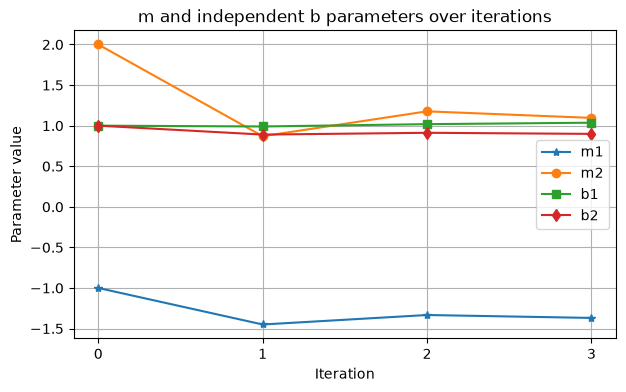

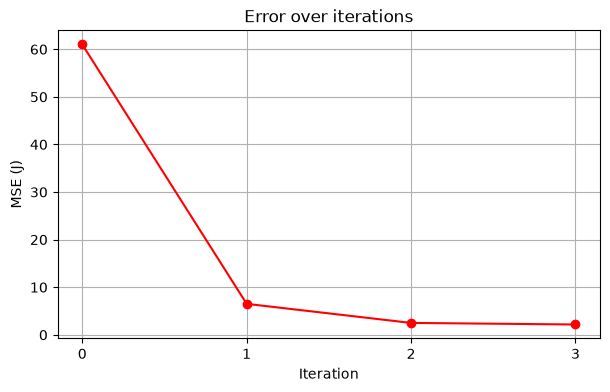

In [18]:
#the plots 
iters = list(range(num_updates + 1))

plt.figure(figsize=(7, 4))
plt.plot(iters, history_m1, marker="*", label="m1")
plt.plot(iters, history_m2, marker="o", label="m2")
plt.plot(iters, history_b1, marker="s", label="b1")
plt.plot(iters, history_b2, marker="d", label="b2")
plt.xlabel("Iteration")
plt.ylabel("Parameter value")
plt.title("m and independent b parameters over iterations")
plt.xticks(iters)
plt.legend()
plt.grid(True)

plt.figure(figsize=(7, 4))
plt.plot(iters, history_J, marker="o", color="red")
plt.xlabel("Iteration")
plt.ylabel("MSE (J)")
plt.title("Error over iterations")
plt.xticks(iters)
plt.grid(True)

plt.show()